# Exercise 5: Sinusoidal model

This exercise explores sinusoidal analysis and tracking using the sinusoidal model from `smstools`. It has four parts:
1. Minimise the frequency estimation error of a sinusoid
2. Track a two-component linear chirp
3. Track sinusoids of very different amplitudes
4. Sinusoidal modelling of a multicomponent signal

### Relevant concepts

**Chirp signals:** A chirp is a signal whose instantaneous frequency changes over time. A *linear* chirp sweeps frequency at a constant rate. Analysing a chirp with the STFT involves a fundamental tradeoff: resolving two closely spaced frequency components requires a *long* window (narrow main lobe), but tracking a rapidly changing frequency requires a *short* window (good time localisation). The optimal window size balances these competing demands.

**Sinusoidal modelling and sine tracking:** The sinusoidal model represents each audio frame as a sum of sinusoids. The `sineModelAnal()` function detects spectral peaks in each frame and links them across frames into *tracks*. The key parameters are:

- `maxnSines`: maximum number of sinusoidal tracks per frame
- `minSineDur`: minimum track duration in seconds (shorter tracks are discarded as spurious)
- `freqDevOffset`: minimum allowed frequency deviation at 0 Hz (sets the tracking tolerance)
- `freqDevSlope`: how much the deviation tolerance grows with frequency (compensates for the tendency of higher-frequency tracks to vary more)

Setting `minSineDur = 0` retains all detected peaks with no duration filtering.

**Tracking low-amplitude sinusoids:** When two sinusoids have very different amplitudes, the *sidelobes* of the stronger component can mask the main lobe of the weaker one. The choice of analysis window is critical: windows with high sidelobe levels (e.g. rectangular) will bury weak components, while windows with strong sidelobe attenuation (e.g. Blackman-Harris) keep sidelobes well below the weak component's main lobe.


## Part 1 – Minimising the frequency estimation error of a sinusoid

The function `min_freq_est_err()` should find the smallest valid window size `M` such that the frequency estimation error is less than 0.05 Hz, and return the estimated frequency along with the parameters used.

**Analysis setup:**
- Window type: Blackman
- Analysis frame: centred at $t = 0.5$ s
- Peak detection threshold: $t = -40$ dB
- Use `dftAnal()`, `peakDetection()`, and `peakInterp()` from `dftModel.py`

**Finding M:** Iterate over candidate window sizes of the form $M = 100k + 1$ for $k = 1, 2, 3, \ldots$ and stop at the first value for which $|f - f_{\mathrm{est}}| < 0.05$ Hz. For each `M`, set the FFT size `N` to the smallest power of 2 larger than `M`.

**Inputs:**
- `input_file` (str): path to a `.wav` file containing a single stationary sinusoid (length ≥ 1 s)
- `f` (float): true frequency of the sinusoid in Hz (range: 100–2000 Hz)

**Output:** tuple `(f_est, M, N)` — estimated frequency in Hz, window size, and FFT size.


In [2]:
import numpy as np
from scipy.signal import get_window
import math
from smstools.models import dftModel as DFT
from smstools.models import utilFunctions as UF
from smstools.models import stft
from smstools.models import sineModel as SM
import IPython.display as ipd

In [15]:
# E5 - 1.1: Complete the function min_freq_est_err()

def min_freq_est_err(input_file, f):
    """Best estimate the frequency of a sinusoid by iterating over different sizes of analysis window.

    Args:
            input_file (str): wav file
            f (float): frequency of the sinusoid present in the input audio signal (Hz)

    Result:
            f_est (float): estimated frequency of the sinusoid (Hz)
            M (int): Window size
            N (int): FFT size

    """
    # analysis parameters:
    window = 'blackman'
    t = -40
    ### Your code here
    fs, x = UF.wavread(input_file)
    delta = 1
    k=0

    while delta >= 0.05:
        k+=1
        M = 100*k + 1
        N = 2 ** math.ceil(math.log2(M))
        w = get_window(window, M)
        center_id = int(0.5*fs)
        hM = M//2

        x_centered = x[center_id-hM:center_id+hM+1]
        mX, pX = DFT.dftAnal(x_centered, w, N)

        ploc = UF.peakDetection(mX, t) #peak location
        if len(ploc) == 0:
                k += 1
                continue
        
        iploc, ipmag, ipphase = UF.peakInterp(mX, pX, ploc)
        f_est = fs*iploc/N

        delta = abs(f_est - f)
        # print(f"M={M}, N={N}, estimate={f_est} Hz, error={delta} Hz")
        
    return f_est, M, N

Test cases for `min_freq_est_err()`:

**Test case 1:** `sine-490.wav`, `f = 490.0 Hz` → `M = 1101`, `N = 2048`, `f_est ≈ 489.963 Hz`, error ≈ 0.037 Hz

**Test case 2:** `sine-1000.wav`, `f = 1000.0 Hz` → `M = 1101`, `N = 2048`, `f_est ≈ 1000.02 Hz`, error ≈ 0.020 Hz

**Test case 3:** `sine-200.wav`, `f = 200.0 Hz` → `M = 1201`, `N = 2048`, `f_est ≈ 200.038 Hz`, error ≈ 0.038 Hz

For each test case, generate a new sinusoid at `f_est` and listen to it alongside the original to check whether the estimation error is perceptually audible.


In [16]:
# E5 - 1.2: For each test case, call min_freq_est_err(), generate and play both the original and the
#            estimated sinusoid, and compare them perceptually.

### Your code here
test_cases = [
    ("sine-490.wav", 490),
    ("sine-1000.wav", 1000),
    ("sine-200.wav", 200)
]

for filename, f in test_cases:
    input_file = f"../sounds/{filename}"
    f_est, M, N = min_freq_est_err(input_file, f)
    print(f"Input file: {filename}, True frequency: {f} Hz, Estimated frequency: {f_est} Hz, Window size: {M}, FFT size: {N}")

    # Generate the estimated sinusoid
    fs, x = UF.wavread(input_file)
    t = np.arange(len(x)) / fs
    estimated_sinusoid = np.sin(2 * np.pi * f_est * t)

    # Play the original and estimated sinusoids
    print("Playing original sinusoid...")
    ipd.display(ipd.Audio(x, rate=fs))
    
    print("Playing estimated sinusoid...")
    ipd.display(ipd.Audio(estimated_sinusoid, rate=fs))


Input file: sine-490.wav, True frequency: 490 Hz, Estimated frequency: [489.9630183] Hz, Window size: 1101, FFT size: 2048
Playing original sinusoid...


Playing estimated sinusoid...


Input file: sine-1000.wav, True frequency: 1000 Hz, Estimated frequency: [1000.01994268] Hz, Window size: 1101, FFT size: 2048
Playing original sinusoid...


Playing estimated sinusoid...


Input file: sine-200.wav, True frequency: 200 Hz, Estimated frequency: [200.03811968] Hz, Window size: 1201, FFT size: 2048
Playing original sinusoid...


Playing estimated sinusoid...


**E5 - 1.3: Conceptual questions (answer here)**

1. Why does a larger window size generally reduce the frequency estimation error? What property of the DFT is responsible? Verify by running `min_freq_est_err` on one test case and printing the error at each candidate `M`.

    A longer window observes more of the sinusoid’s cycles. That makes its frequency peak narrower, so its location can usually be estimated more precisely. In the DFT, the bin spacing is (f_s/N); increasing the window length generally increases N too, making bins closer together. Peak interpolation can estimate between bins, but a longer observation usually helps.

2. For the test cases above, the optimal `M` is around 1100–1200 samples. Does the required `M` depend on the frequency `f`? Try `f = 300 Hz` and `f = 1500 Hz` and compare the optimal `M` values. Explain the trend (or lack of one).

    It depends on the f - it can be because of the grid resolution (bin resolution) and the size of M (the bigger the better).

    There isn’t a guaranteed trend from frequency alone: the bin spacing in Hz is determined by fs/N, while peak interpolation and the signal’s phase/window alignment can affect the measured error. A higher-frequency tone has more cycles in the same window, but that does not necessarily mean it will meet this particular error tolerance with a smaller M.

3. Can you hear a difference between the original and estimated sinusoids for any of the three test cases? What does this tell you about the perceptual relevance of a 0.05 Hz estimation error?

    I can't. For a short tone, a frequency error smaller than 0.05 Hz is generally too small to notice by listening. The two tones would drift in phase very slowly; a 0.05 Hz difference corresponds to a 20-second beat period. This shows that the exercise’s numerical accuracy target is stricter than what you’d typically judge from a brief listening comparison. 


## Part 2 – Tracking a two-component linear chirp

Use `freq_tracker_error()` to find the window size `M` that best tracks both frequency components of `chirp-150-190-linear.wav`, aiming for a mean estimation error below 2 Hz on each component.

The file contains a two-component linear chirp: one sinusoid sweeping from 150 Hz to 1400 Hz and another from 190 Hz to 1440 Hz, both over 2 seconds. The two components are only 40 Hz apart throughout, so resolving them requires a large window — but a very large window will smear the rapidly changing frequencies. Finding the right balance is the core challenge.

**Fixed parameters:** `window = 'blackman'`, `t = -80`, `H = 128`.

**Your task:** Choose `M` analytically (think about the frequency separation and the required main-lobe width), then verify with `freq_tracker_error()`. Plot the true vs. estimated frequency tracks for both your initial choice (`M = 1023` as a baseline) and your improved value.

> Tip: use `gen_time_stamps()` to generate the time axis and `gen_true_freq_tracks_chirp_150_190()` to get the reference tracks for comparison.


In [71]:
# functions used in exercises of Part 2 and 3

def gen_time_stamps(xlen, M, fs, H):
    """Generate frame time stamps for a given signal length and sampling rate.

    Args:
        xlen (int): duration of signal in samples
        M (int): window size
        fs (int): sampling rate
        H (int): hop size

    Result:
        np.array: time stamps

    """
    hM1 = int(np.floor((M+1)/2))
    hM2 = int(np.floor(M/2))
    xlen = xlen + 2*hM2
    pin = hM1
    pend = xlen - hM1
    tStamps = np.arange(pin,pend,H)/float(fs)
    return tStamps

def gen_true_freq_tracks_chirp_150_190(tStamps):
    """Generate the frequency values present in file "../sounds/chirp-150-190-linear.wav"

    Args:
        tStamps (np.array): time stamps

    Result:
        np.array: time stamps and frequency values of predefined chirp

    """
    fTrack = np.zeros((len(tStamps),2))
    fTrack[:,0] = np.transpose(np.linspace(190, 190+1250, len(tStamps)))
    fTrack[:,1] = np.transpose(np.linspace(150, 150+1250, len(tStamps)))
    return fTrack

def gen_true_freq_tracks_440_602(tStamps):
    """Generate the frequency values present in file "../sounds/sines-440-602-hRange.wav"

    Args:
        tStamps (np.array): time stamps

    Result:
        np.array: time stamps and frequency values of predefined chirp

    """
    fTrack = np.zeros((len(tStamps),2))
    fTrack[:,0] = np.transpose(440*np.ones((len(tStamps),1)))
    fTrack[:,1] = np.transpose(602*np.ones((len(tStamps),1)))
    return fTrack

def freq_tracker_error(input_file, fTrackTrue, window, t, H, M):
    """Estimate sinusoidal values of a sound

    Args:
        input_file (str): wav file including the path
        fTrackTrue (np.array): array of true frequency values, one row per time frame, one column per component
        window (str): window type used for analysis
        t (float): peak picking threshold (negative dB)
        H (int): hop size in samples
        M (int): window size in samples

   Result:
           float: mean estimation error
           np.array: estimated frequency values, one row per time frame, one column per component

    """

    N = int(pow(2, np.ceil(np.log2(M))))        # FFT Size, power of 2 larger than M
    maxnSines = 2                               # Maximum number of sinusoids at any time frame
    minSineDur = 0.0                            # minimum duration set to zero to not do tracking
    freqDevOffset = 30                          # minimum frequency deviation at 0Hz
    freqDevSlope = 0.001                        # slope increase of minimum frequency deviation

    fs, x = UF.wavread(input_file)              # read input sound
    w = get_window(window, M)                   # Compute analysis window
    # analyze the sound with the sinusoidal model
    fTrackEst, mTrackEst, pTrackEst = SM.sineModelAnal(x, fs, w, N, H, t, maxnSines, minSineDur, freqDevOffset, freqDevSlope)
    tailF = 20
    # Compute mean estimation error. 20 frames at the beginning and end not used to compute error
    meanErr = np.mean(np.abs(fTrackTrue[tailF:-tailF,:] - fTrackEst[tailF:-tailF,:]),axis=0)

    return (meanErr, fTrackEst)

**Baseline test case:** `M = 1023` gives mean errors of `[13.7, 528.5]` Hz — far above the 2 Hz target. The second component is almost completely untracked.

Start by reasoning about **why** `M = 1023` fails: what is the main-lobe width in Hz for that window size at the sampling rate of the file? Is it narrow enough to resolve components 40 Hz apart? Then calculate the minimum `M` theoretically, test it, and refine.


Mean errors for M = 1023 : [ 13.66932655 559.49786224] Hz
Mean errors for M = 6615 : [197.4604435  221.22366867] Hz
Mean errors for M = 3501 : [0.85634738 1.66958553] Hz
Mean errors for M = 4501 : [0.85634738 1.66958553] Hz


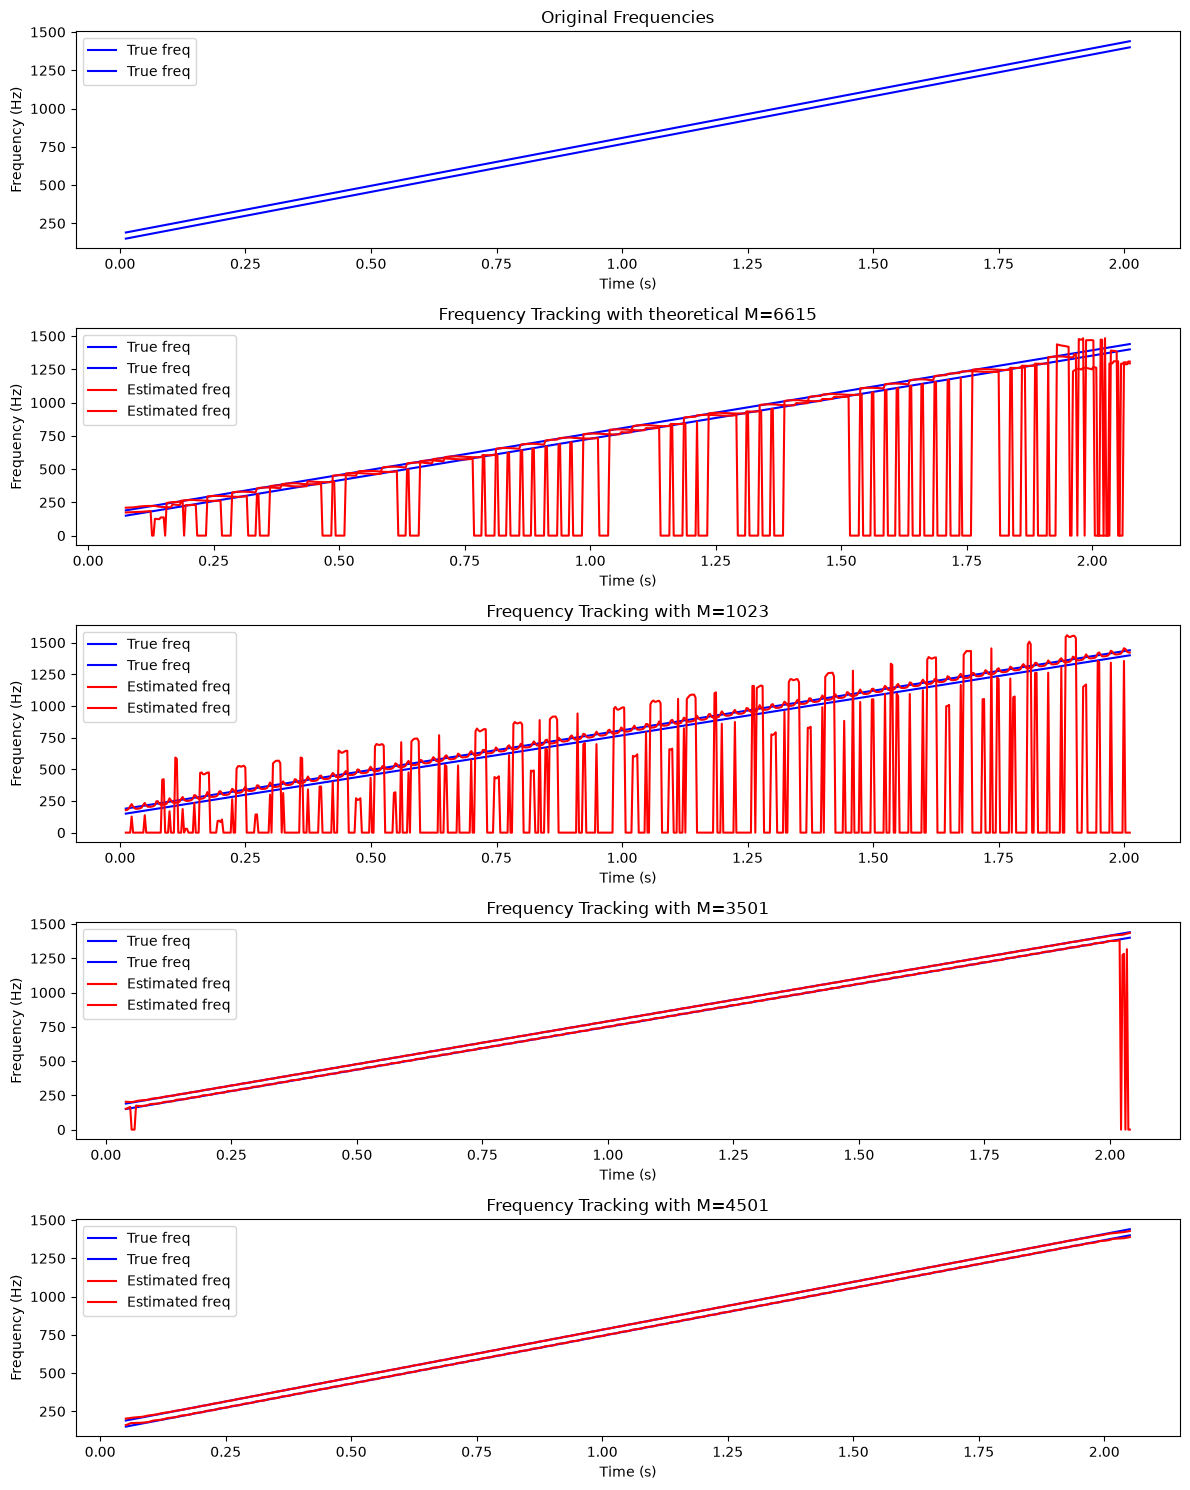

In [72]:
# E5 - 2.1: Call freq_tracker_error() with the baseline M=1023 and plot true vs estimated tracks.
#            Then find and apply an improved M, and plot the new estimated tracks.

import matplotlib.pyplot as plt

H = 128
window = 'blackman'
t = -80
input_file = '../sounds/chirp-150-190-linear.wav'
fs, x = UF.wavread(input_file)

# baseline test
M1 = 1023
tStamps1 = gen_time_stamps(x.size, M1, fs, H)
fTrackTrue1 = gen_true_freq_tracks_chirp_150_190(tStamps1)
meanErr1, fTrackEst1 = freq_tracker_error(input_file, fTrackTrue1, window, t, H, M1)
print(f"Mean errors for M = {M1} : {meanErr1} Hz")

# theoretical
Mt = int(6*fs/40)
tStampst = gen_time_stamps(x.size, Mt, fs, H)
fTrackTruet = gen_true_freq_tracks_chirp_150_190(tStampst)
meanErrt, fTrackEstt = freq_tracker_error(input_file, fTrackTruet, window, t, H, Mt)
print(f"Mean errors for M = {Mt} : {meanErrt} Hz")

# 1st trial
M2 = 3501
tStamps2 = gen_time_stamps(x.size, M2, fs, H)
fTrackTrue2 = gen_true_freq_tracks_chirp_150_190(tStamps2)
meanErr2, fTrackEst2 = freq_tracker_error(input_file, fTrackTrue2, window, t, H, M2)
print(f"Mean errors for M = {M2} : {meanErr2} Hz")

# 2nd trial
M3 = 4501
tStamps3 = gen_time_stamps(x.size, M3, fs, H)
fTrackTrue3 = gen_true_freq_tracks_chirp_150_190(tStamps3)
meanErr3, fTrackEst3 = freq_tracker_error(input_file, fTrackTrue3, window, t, H, M3)
print(f"Mean errors for M = {M3} : {meanErr2} Hz")


# Plot test case
plt.figure(1, figsize=(12, 15))
plt.subplot(511)
plt.plot(tStamps1, fTrackTrue1, 'b', label='True freq')
plt.title('Original Frequencies')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.legend()
plt.subplot(512)
plt.plot(tStampst, fTrackTruet, 'b', label='True freq')
plt.plot(tStampst, fTrackEstt, 'r', label='Estimated freq')
plt.title(f'Frequency Tracking with theoretical M={Mt}')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.legend()
plt.subplot(513)
plt.plot(tStamps1, fTrackTrue1, 'b', label='True freq')
plt.plot(tStamps1, fTrackEst1, 'r', label='Estimated freq')
plt.title(f'Frequency Tracking with M={M1}')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.legend()
plt.subplot(514)
plt.plot(tStamps2, fTrackTrue2, 'b', label='True freq')
plt.plot(tStamps2, fTrackEst2, 'r', label='Estimated freq')
plt.title(f'Frequency Tracking with M={M2}')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.legend()
plt.subplot(515)
plt.plot(tStamps3, fTrackTrue3, 'b', label='True freq')
plt.plot(tStamps3, fTrackEst3, 'r', label='Estimated freq')
plt.title(f'Frequency Tracking with M={M3}')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.legend()
plt.tight_layout()
plt.show()  

**E5 - 2.3: Conceptual questions (answer here)**

1. What is the Blackman window's main-lobe width (in Hz) for `M = 1023` at the sampling rate of the chirp file? Is it narrow enough to resolve two components 40 Hz apart? Repeat the calculation for your improved `M`.

    A Blackman window’s null-to-null main-lobe width is approximately 6 (f_s/M) Hz. For M=1023 and fs=44100 Hz: `6*44100/1023 = 258 Hz`. That is much wider than the 40 Hz separation, so the two components are not cleanly resolved. 
    
    For my improved window its: `6*44100/4501 = 59 Hz`. For example, M=6615 gives about 40 Hz, which is only borderline; a longer window gives a narrower lobe and better separation. Zero-padding (N) makes the plotted spectrum denser but does not narrow the window’s actual main lobe.

2. Increasing `M` improves frequency resolution but degrades time resolution. From your plot of the estimated frequency tracks, do you observe any blurring or smearing of the chirp trajectory for large `M`? At what window size does this become visible?

    A larger M improves frequency separation but averages over a longer part of the changing chirp, so the estimated tracks can lag or smear around rapid frequency changes. At 44.1 kHz, M=1023 spans about 23 ms, while M=6615 spans about 150 ms. Look for the smearing in your improved track plot; it becomes more noticeable when that longer window spans enough of the chirp’s motion to blur its trajectory. State the M where you first see it in your plot.

3. The first and last 20 frames (`tailF = 20`) are excluded from the error calculation. Why? What happens to the frequency tracks in those boundary regions?

    The first and last 20 frames are near the recording boundaries. Their analysis windows extend partly beyond the available audio, where the STFT uses zero padding. Those frames have less real signal context, so their peaks and frequency estimates can be missing or unreliable. Excluding them keeps these edge effects from distorting the mean tracking-error calculation.


## Part 3 – Tracking sinusoids of different amplitudes

Use `freq_tracker_error()` to find the window type `window` and magnitude threshold `t` that best track both sinusoids in `sines-440-602-hRange.wav`, aiming for a mean estimation error below 2 Hz on each component.

The signal is $s = \sin(2\pi \cdot 440 \cdot t) + 2\times10^{-3}\sin(2\pi \cdot 602 \cdot t)$: one component at 440 Hz and a second at 602 Hz that is **1000 times weaker** (−60 dB). The weak component's main lobe must be detectable above the sidelobes of the dominant component.

**Fixed parameters:** `M = 2047`, `N = 4096`, `H = 128`, `minSineDur = 0.02`, `freqDevOffset = 10`, `freqDevSlope = 0.001`, `maxnSines = 2`.

**Your task:** Choose `window` based on its sidelobe attenuation (compare `'boxcar'`, `'hanning'`, `'hamming'`, `'blackman'`, `'blackmanharris'`), and set `t` (in dB, negative) to capture the weak component without picking up noise. Plot the true vs. estimated tracks for the baseline (`window='hanning'`, `t=-80`) and your improved parameters.

**Baseline test case:** `window = 'hanning'`, `t = -80` → mean errors `[0.196, 29.5]` Hz. The weak 602 Hz component is tracked poorly.


In [73]:
M = 2047
N = 4096
H = 128
input_file = '../sounds/sines-440-602-hRange.wav'
fs, x = UF.wavread(input_file)
tStamps = gen_time_stamps(x.size, M, fs, H)
fTrackTrue = gen_true_freq_tracks_440_602(tStamps)

for window in ["hann", "blackman", "blackmanharris"]:
    for t in [-70, -80, -90, -100, -105, -110, -115, -120]:
        errors, estimated = freq_tracker_error(
            input_file, fTrackTrue, window, t, H, M
        )
        print(f"{window:14s} t={t:4d}: errors={errors}")

hann           t= -70: errors=[1.96037014e-01 2.71075100e+02]
hann           t= -80: errors=[1.96037014e-01 2.71075100e+02]
hann           t= -90: errors=[1.96037014e-01 2.71075100e+02]
hann           t=-100: errors=[1.96037014e-01 2.71075100e+02]
hann           t=-105: errors=[1.96037014e-01 2.69195810e+02]
hann           t=-110: errors=[1.96037014e-01 3.49839830e+02]
hann           t=-115: errors=[1.96037014e-01 4.07257277e+02]
hann           t=-120: errors=[1.96037014e-01 4.53252638e+02]
blackman       t= -70: errors=[7.99435489e-02 6.02000000e+02]
blackman       t= -80: errors=[7.99435489e-02 6.02000000e+02]
blackman       t= -90: errors=[7.99435489e-02 4.84411861e+02]
blackman       t=-100: errors=[7.99435489e-02 4.84856995e+02]
blackman       t=-105: errors=[7.99435489e-02 4.81976804e+02]
blackman       t=-110: errors=[7.99435489e-02 4.63589433e+02]
blackman       t=-115: errors=[7.99435489e-02 4.72794705e+02]
blackman       t=-120: errors=[7.99435489e-02 5.18520002e+02]
blackman

Mean errors for test case values : [1.96037014e-01 2.71075100e+02] Hz
Mean errors for optimal values : [3.84379361e-02 3.12748104e+02] Hz


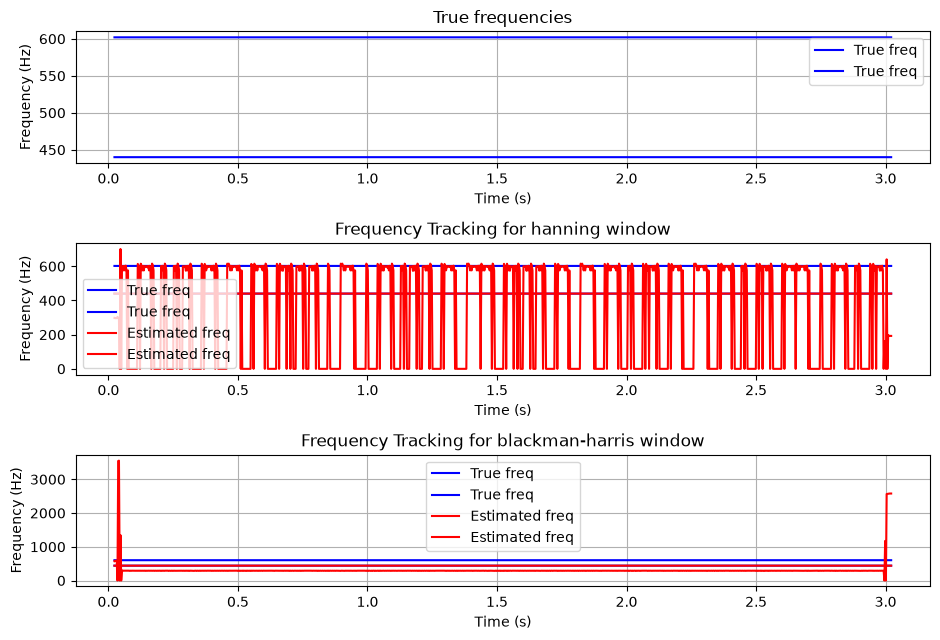

In [74]:
# E5 - 3.1: Call freq_tracker_error() with the baseline parameters and plot true vs estimated tracks.
#            Then choose the best window and threshold, and plot the improved results.

M = 2047
N = 4096
H = 128
input_file = '../sounds/sines-440-602-hRange.wav'
fs, x = UF.wavread(input_file)
tStamps = gen_time_stamps(x.size, M, fs, H)
fTrackTrue = gen_true_freq_tracks_440_602(tStamps)

### Your code here

window = 'hann'
t = -80.0
meanErr, fTrackEst = freq_tracker_error(input_file, fTrackTrue, window, t, H, M)

print(f"Mean errors for test case values : {meanErr} Hz")

#Chosen values
window1 = 'blackmanharris'
t1 = -110.0
meanErr1, fTrackEst1 = freq_tracker_error(input_file, fTrackTrue, window1, t1, H, M)

print(f"Mean errors for optimal values : {meanErr1} Hz")

# Plots
plt.figure(1, figsize=(9.5, 6.5))
plt.subplot(311)
plt.plot(tStamps, fTrackTrue, 'b', label='True freq')
plt.title('True frequencies')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.legend()
plt.grid(True)
plt.subplot(312)
plt.plot(tStamps, fTrackTrue, 'b', label='True freq')
plt.plot(tStamps, fTrackEst, 'r', label='Estimated freq')
plt.title('Frequency Tracking for hanning window')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.legend()
plt.subplot(313)
plt.plot(tStamps, fTrackTrue, 'b', label='True freq')
plt.plot(tStamps, fTrackEst1, 'r', label='Estimated freq')
plt.title('Frequency Tracking for blackman-harris window')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

**E5 - 3.3: Conceptual questions (answer here)**

1. Look up (or compute) the sidelobe attenuation of the Hanning and Blackman-Harris windows. The weak sinusoid is −60 dB relative to the dominant one. Which window types have sidelobe levels low enough to keep the weak component's main lobe visible? Confirm with your experimental results.

   Hann’s highest sidelobe is about −31 dB, Blackman’s is around −58 dB, and four-term Blackman–Harris is around −92 dB. The weak sinusoid is −60 dB relative to the strong one, so Hann’s sidelobes can mask it. Blackman is borderline: its sidelobes are close to the weak tone’s level. Blackman–Harris should suppress them sufficiently in theory, but your reported Blackman result [0.038, 602] shows that the weak tone still was not tracked with the settings you tested. Try Blackman–Harris and verify its errors and plot before claiming success.

2. Why does lowering the magnitude threshold `t` help track the weak component? What is the risk of setting `t` too low (e.g., `t = -120 dB`)?

    Lowering the threshold t allows quieter peaks to be detected, which can help find the weak tone. But it cannot reliably distinguish that tone from strong-tone sidelobes if those sidelobes are too high. Setting t too low (for example, −120 dB) can admit noise and spurious peaks, leading to false tracks or track swaps.

3. With `window = 'hanning'` and `t = -80`, the 602 Hz component has error ≈ 30 Hz. From the frequency-track plot, does the tracker follow a sidelobe of the 440 Hz sinusoid instead of the 602 Hz main lobe? How can you tell?

    Your current Hann plot does not show enough evidence to say that sidelobes explain the whole error. When its estimated track is present, it appears near 600 Hz—close to the weak tone. The frequent drops to zero suggest many frames have no valid second track; those missing frames can explain a large mean error. The stated “about 30 Hz” is the exercise’s baseline result, but your measured error is about 271 Hz, so report your actual result and note the discrepancy.

## Part 4 – Sinusoidal modelling of a multicomponent signal

Perform the best possible sinusoidal analysis of `multiSines.wav` by exploring the `sineModelAnal()` parameters. The goal is a resynthesised sound that is perceptually indistinguishable from the input.

`multiSines.wav` combines several challenging features simultaneously:
- Sharp amplitude attacks
- Closely spaced frequency components across a wide amplitude range
- Time-varying chirp tracks that cross over in frequency

Listen to the sound and examine its spectrogram (using `models_GUI.py` or Sonic Visualizer) before choosing parameters.

**Parameters to set:** `window`, `M`, `N`, `t`, `minSineDur`, `maxnSines`, `freqDevOffset`, `freqDevSlope`.

The synthesis parameters `Ns = 512` and `H = 128` are fixed — do not modify them.

> This is an open-ended exploration. Start with a reasonable set of parameters, listen to the output, examine the frequency tracks, and iterate.


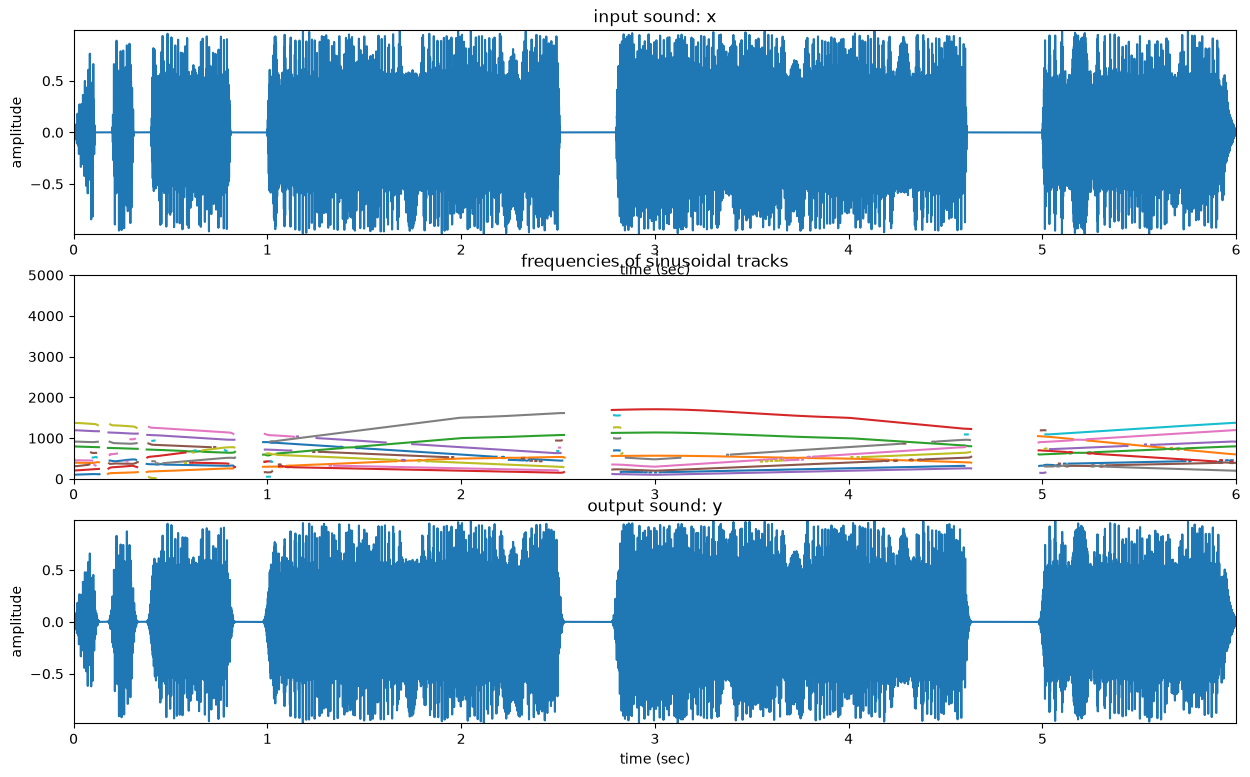

In [129]:
# E5 - 4.1: 
# Set the analysis parameters of sineModelAnal() to perform the best analysis of multiSines.wav

import IPython.display as ipd

input_file = '../sounds/multiSines.wav'

### set the analysis parameters

window = 'blackman'
M = 3001
N = int(2 ** np.ceil(np.log2(M)))
t = -70
minSineDur = 0.01
maxnSines = 10
freqDevOffset = 20
freqDevSlope = 0.001


# no need to modify the code after here
Ns = 512                                      # size of fft used in synthesis
H = 128                                       # hop size (has to be 1/4 of Ns)

fs, x = UF.wavread(input_file)                # read input sound
w = get_window(window, M)                     # compute analysis window

# analyze the sound with the sinusoidal model
tfreq, tmag, tphase = SM.sineModelAnal(x, fs, w, N, H, t, maxnSines, minSineDur, freqDevOffset, freqDevSlope)

# synthesize the output sound from the sinusoidal representation
y = SM.sineModelSynth(tfreq, tmag, tphase, Ns, H, fs)

# create figure to show plots
plt.figure(figsize=(15, 9))

# frequency range to plot
maxplotfreq = 5000.0

# plot the input sound
plt.subplot(3,1,1)
plt.plot(np.arange(x.size)/float(fs), x)
plt.axis([0, x.size/float(fs), min(x), max(x)])
plt.ylabel('amplitude')
plt.xlabel('time (sec)')
plt.title('input sound: x')

# plot the sinusoidal frequencies
plt.subplot(3,1,2)
if (tfreq.shape[1] > 0):
    numFrames = tfreq.shape[0]
    frmTime = H*np.arange(numFrames)/float(fs)
    tfreq[tfreq<=0] = np.nan
    plt.plot(frmTime, tfreq)
    plt.axis([0, x.size/float(fs), 0, maxplotfreq])
    plt.title('frequencies of sinusoidal tracks')

# plot the output sound
plt.subplot(3,1,3)
plt.plot(np.arange(y.size)/float(fs), y)
plt.axis([0, y.size/float(fs), min(y), max(y)])
plt.ylabel('amplitude')
plt.xlabel('time (sec)')
plt.title('output sound: y')

ipd.display(ipd.Audio(data=x, rate=fs))
ipd.display(ipd.Audio(data=y, rate=fs))

**E5 - 4.3: Conceptual questions (answer here)**

1. Describe the main challenges you identified in `multiSines.wav` from the spectrogram. Which feature was hardest to handle — the sharp attacks, the wide amplitude range, or the crossing chirp tracks? Explain why.

    The signal combines sharp attacks, components with a wide range of amplitudes, and chirps that cross. The weakest components may be difficult to detect because stronger components can mask them; the crossing tracks can also be difficult to keep assigned consistently.

2. Report the final parameter values you chose (`window`, `M`, `t`, `maxnSines`, `minSineDur`, `freqDevOffset`, `freqDevSlope`). For each parameter, explain *why* you chose that value, linking it to a specific property of the signal.

    ...

3. Listen carefully to the resynthesised output. Are there any audible artefacts or missing components? If so, describe them and explain which aspect of the sinusoidal model is responsible.

    ...

4. Is there a single parameter set that handles all the challenging features of this signal simultaneously, or did you have to make tradeoffs? Describe any tradeoffs you encountered.

    ...
